# Statistical Traps: Simpson, Regression to the Mean, p-Hacking

**What you'll learn**

- Simpson's paradox in a realistic product setting (a staged rollout that flips sign when
  you segment by device) — and the **confounder criterion** that tells you whether the
  aggregated or the segmented number is the right one. It is a causal question, not a taste question.
- Regression to the mean: why "we coached the worst performers and they improved 50%" is
  the expected outcome of doing *nothing*, how to predict the artifact analytically from
  measurement reliability, and the randomized design that fixes it.
- Multiple testing at analytics scale: an A/A experiment scanned across 20 metrics × 100
  segments, the family-wise error blowup, and the mechanics of Bonferroni / Holm / Benjamini–
  Hochberg — with a decision rule for which correction fits which analytics job.
- The garden of forking paths: optional stopping plus subgroup mining manufacturing
  "significant" results from pure noise, with the combined false-positive rate quantified.
- Winner's curse / Type M error: conditioning on significance at low power *guarantees*
  exaggerated estimates — we quantify the exaggeration ratio by simulation and show what it
  does to a year's worth of "shipped wins."
- Survivorship and collider (Berkson) bias: surveying only retained users, and why team
  quality and idea quality look negatively correlated *among funded startups* even when
  they aren't in the population.

**Why it matters in interviews**

- "Your A/B result reverses when you segment it — what do you do?" is a canonical senior
  screen. The expected answer is a causal argument (confounder vs mediator/collider, SRM
  check), not "report both numbers."
- Experiment-review rounds love "the team ran 40 tests and 3 are significant — now what?"
  and "why did the effect shrink when we re-ran the winner?" Both are tests of whether you
  reason about selection on noise.
- Case interviews plant regression-to-the-mean traps constantly ("our intervention on the
  worst X improved them") — spotting it instantly is a strong senior signal.
- Metric-design questions ("what could go wrong if we optimize this?") are Goodhart
  questions in disguise.

Prerequisites: sampling distributions from
[01_sampling_clt_bootstrap.ipynb](./01_sampling_clt_bootstrap.ipynb) and the behavior of
p-values under H0 from
[02_hypothesis_testing_beyond_basics.ipynb](./02_hypothesis_testing_beyond_basics.ipynb).
The causal machinery behind "good vs bad controls" is developed properly in
[../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb);
legitimate sequential monitoring (peeking done right) lives in
[../02_ab_testing/04_peeking_sequential.ipynb](../02_ab_testing/04_peeking_sequential.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)

## 1. Simpson's paradox: the sign flip is real, the question is causal

**Scenario.** A new checkout flow was ramped up platform-by-platform: it launched on
mobile first, so during the comparison window the *new-flow* group is 80% mobile while the
*old-flow* group is 30% mobile. Mobile converts far worse than desktop everywhere in
e-commerce. Ground truth in the simulation: the new flow lifts conversion by **+25%
relative within each device** (8% → 10% desktop, 3% → 3.75% mobile).

This is not an edge case. Any comparison where exposure correlates with a strong
conversion driver (device, country, tenure, weekday, acquisition channel) can flip sign
under aggregation.

In [2]:
n_per_group = 300_000

def simulate_checkout(n, mobile_share, conv_desktop, conv_mobile, label):
    device = np.where(rng.random(n) < mobile_share, "mobile", "desktop")
    p = np.where(device == "mobile", conv_mobile, conv_desktop)
    converted = rng.random(n) < p
    return pd.DataFrame({"group": label, "device": device, "converted": converted})

checkout = pd.concat([
    simulate_checkout(n_per_group, 0.30, 0.080, 0.0300, "old flow"),
    simulate_checkout(n_per_group, 0.80, 0.100, 0.0375, "new flow"),
], ignore_index=True)

overall = checkout.groupby("group", sort=False)["converted"].agg(["mean", "size"])
by_device = (checkout.groupby(["device", "group"], sort=False)["converted"]
             .agg(["mean", "size"]).unstack("group"))

print("AGGREGATE conversion:")
print((overall["mean"] * 100).round(2).astype(str) + " %")
agg_lift = overall.loc["new flow", "mean"] / overall.loc["old flow", "mean"] - 1
print(f"\naggregate relative lift of new flow: {agg_lift:+.1%}   <-- looks like a disaster")

print("\nBY DEVICE (conversion %):")
seg = (by_device["mean"] * 100).round(2)
seg["relative lift"] = (by_device["mean"]["new flow"] /
                        by_device["mean"]["old flow"] - 1).map("{:+.1%}".format)
seg["n old"] = by_device["size"]["old flow"]
seg["n new"] = by_device["size"]["new flow"]
print(seg)

AGGREGATE conversion:
group
old flow    6.52 %
new flow    4.99 %
Name: mean, dtype: object

aggregate relative lift of new flow: -23.4%   <-- looks like a disaster

BY DEVICE (conversion %):
group    old flow  new flow relative lift   n old   n new
device                                                   
desktop      8.04      9.87        +22.8%  209926   60317
mobile       2.98      3.77        +26.3%   90074  239683


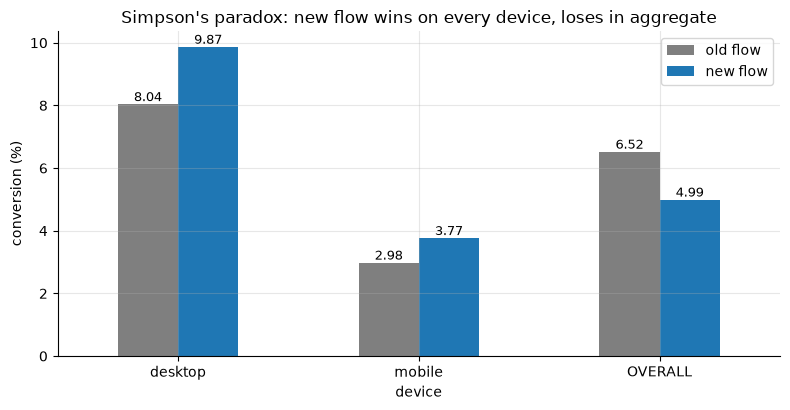

In [3]:
fig, ax = plt.subplots()
plot_df = (by_device["mean"] * 100)
plot_df.loc["OVERALL"] = overall["mean"] * 100
plot_df.plot.bar(ax=ax, rot=0, color=["tab:gray", "tab:blue"])
ax.set_ylabel("conversion (%)")
ax.set_title("Simpson's paradox: new flow wins on every device, loses in aggregate")
for i, (idx, row) in enumerate(plot_df.iterrows()):
    for j, v in enumerate(row):
        ax.annotate(f"{v:.2f}", (i + (j - 0.5) * 0.25, v), ha="center",
                    va="bottom", fontsize=9)
ax.legend(title="")
plt.show()

### The confounder criterion: which number do you trust?

Both numbers are arithmetically correct. The choice between them is **causal**, and the
rule is about *where the segmenting variable sits relative to treatment assignment*:

- **Segment (adjust) when the variable is a pre-treatment confounder** — it influences both
  *which group a unit landed in* and *the outcome*. Here device is exactly that: the rollout
  schedule made device predict exposure, and device strongly predicts conversion. The
  aggregate mixes a treatment effect with a composition effect; the segmented numbers (or a
  standardized combination of them, below) estimate the causal effect.
- **Do NOT segment on post-treatment variables** — mediators (things the treatment changes
  on the causal path to the outcome) or colliders (things caused by both treatment and
  outcome, e.g. "made it to step 3 of the funnel"). Conditioning on those *destroys* a real
  effect or manufactures a fake one; the aggregate is the honest number. We demonstrate the
  mediator case right below and the collider case in Section 6.
- **In a healthy randomized A/B test**, pre-treatment covariates are balanced by design, so
  Simpson flips should not happen from confounding. If the mix differs between arms, that is
  a **sample ratio mismatch / broken randomization signal** — investigate the assignment
  mechanism before believing *either* number
  (see [../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb)).

The aesthetic heuristics people actually use — "segmented is more granular, so it's better"
or "the aggregate is the real business number" — are both wrong as *rules*. Each is correct
in the situation its causal structure earns.

**Fixing the estimate here (direct standardization).** Weight the within-device effects by
a *fixed* device mix — e.g. the old-flow mix — instead of letting each arm bring its own:

In [4]:
mix_old = checkout.loc[checkout["group"] == "old flow", "device"].value_counts(normalize=True)
p_seg = by_device["mean"]

standardized = {g: (p_seg[g] * mix_old).sum() for g in ["old flow", "new flow"]}
std_lift = standardized["new flow"] / standardized["old flow"] - 1
print("device mix used as weights (old-flow mix):")
print(mix_old.round(3).to_string())
print(f"\nstandardized conversion  old flow: {standardized['old flow']:.4f}"
      f"   new flow: {standardized['new flow']:.4f}")
print(f"standardized relative lift: {std_lift:+.1%}   (ground truth: +25%)")
print(f"naive aggregate lift:       {agg_lift:+.1%}   (composition artifact)")

device mix used as weights (old-flow mix):
device
desktop    0.7
mobile     0.3

standardized conversion  old flow: 0.0652   new flow: 0.0804
standardized relative lift: +23.2%   (ground truth: +25%)
naive aggregate lift:       -23.4%   (composition artifact)


Standardization recovers the ground truth (+23% estimated vs +25% true) from the same
data whose aggregate "showed" a 23% loss.
This is the simplest member of the adjustment family (regression adjustment, propensity
weighting) covered in
[../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb](../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb).

### The mirror image: segmenting on a *post-treatment* variable erases a real effect

Now a genuinely randomized experiment. The new flow works **entirely** by getting more
people to add to cart (30% → 45%); conversion given cart status is identical in both arms.
Add-to-cart is a *mediator*. Watch what conditioning on it does:

In [5]:
n_arm = 100_000
treat = np.repeat([0, 1], n_arm)
p_cart = np.where(treat == 1, 0.45, 0.30)
cart = rng.random(2 * n_arm) < p_cart
p_buy = np.where(cart, 0.20, 0.02)
buy = rng.random(2 * n_arm) < p_buy

med = pd.DataFrame({"group": np.where(treat == 1, "new flow", "old flow"),
                    "added_to_cart": cart, "purchased": buy})
overall_m = med.groupby("group", sort=False)["purchased"].mean()
by_cart = med.groupby(["added_to_cart", "group"], sort=False)["purchased"].mean().unstack()

print("purchase rate overall:")
print((overall_m * 100).round(2).astype(str) + " %")
print(f"  -> true causal effect, visible in aggregate: "
      f"{(overall_m['new flow'] - overall_m['old flow']) * 100:+.2f} pp")
print("\npurchase rate within add-to-cart strata:")
print((by_cart * 100).round(2))
print("  -> ~zero 'effect' in every stratum: the mediator absorbed it")

purchase rate overall:
group
old flow     7.3 %
new flow    10.0 %
Name: purchased, dtype: object
  -> true causal effect, visible in aggregate: +2.70 pp

purchase rate within add-to-cart strata:
group          old flow  new flow
added_to_cart                    
False              1.98      2.03
True              19.72     19.76
  -> ~zero 'effect' in every stratum: the mediator absorbed it


Same surface phenomenon — "the result changes when we segment" — opposite correct answer.
An analyst whose reflex is *always segment* would report this real +2.7 pp win as a null.
The criterion is causal structure, never granularity:

| segmenting variable is… | example | trust |
|---|---|---|
| pre-treatment confounder (predicts exposure + outcome) | device in a staged rollout | **segmented / standardized** |
| pre-treatment, balanced by randomization | device in a clean A/B | either (segment only for exploration) |
| post-treatment mediator | add-to-cart, engagement after treatment | **aggregate** |
| post-treatment collider / selection gate | "reached checkout", "responded to survey" | **aggregate** (and worry) |

## 2. Regression to the mean: "coaching the worst performers worked"

**Scenario.** Sales ops measures quarterly performance scores for 20,000 reps. True skill
varies across reps ($\sigma_{\text{skill}} = 10$ around a mean of 100), but a single
quarter's score is noisy ($\sigma_{\text{noise}} = 20$ — deal luck, territory shocks).
Leadership sends the **bottom decile of Q1** to a coaching program and re-measures in Q2.

In the simulation below the coaching program does **nothing** — Q2 is just skill plus fresh
noise. The artifact is fully predictable from the **reliability** of the score:

$$\rho \;=\; \frac{\sigma^2_{\text{skill}}}{\sigma^2_{\text{skill}} + \sigma^2_{\text{noise}}}
\qquad\Rightarrow\qquad \mathbb{E}[Y_2 \mid Y_1] \;=\; \mu + \rho\,(Y_1 - \mu)$$

With $\rho = 100/(100+400) = 0.2$, anyone selected 40 points below the mean is *expected*
to bounce back 32 of those points with zero intervention.

In [6]:
n_reps_emp = 20_000
sigma_skill, sigma_noise, mu = 10.0, 20.0, 100.0
true_skill = rng.normal(mu, sigma_skill, n_reps_emp)
q1 = true_skill + rng.normal(0, sigma_noise, n_reps_emp)
q2 = true_skill + rng.normal(0, sigma_noise, n_reps_emp)   # NO intervention at all

rho = sigma_skill**2 / (sigma_skill**2 + sigma_noise**2)
bottom = q1 <= np.quantile(q1, 0.10)
top = q1 >= np.quantile(q1, 0.90)

rows = []
for name, mask in [("bottom decile of Q1", bottom), ("top decile of Q1", top),
                   ("everyone", np.ones_like(bottom))]:
    m1, m2 = q1[mask].mean(), q2[mask].mean()
    rows.append({"cohort": name, "Q1 mean": m1, "Q2 mean": m2, "change": m2 - m1,
                 "predicted Q2 (reliability formula)": mu + rho * (m1 - mu)})
rtm = pd.DataFrame(rows).set_index("cohort")
print(f"score reliability rho = {rho:.2f}\n")
print(rtm.round(2))
print("\nNothing happened between Q1 and Q2 — no coaching, no learning, no attrition.")

score reliability rho = 0.20

                     Q1 mean  Q2 mean  change  \
cohort                                          
bottom decile of Q1    60.41    91.81   31.40   
top decile of Q1      139.79   107.83  -31.96   
everyone              100.23   100.19   -0.04   

                     predicted Q2 (reliability formula)  
cohort                                                   
bottom decile of Q1                               92.08  
top decile of Q1                                 107.96  
everyone                                         100.05  

Nothing happened between Q1 and Q2 — no coaching, no learning, no attrition.


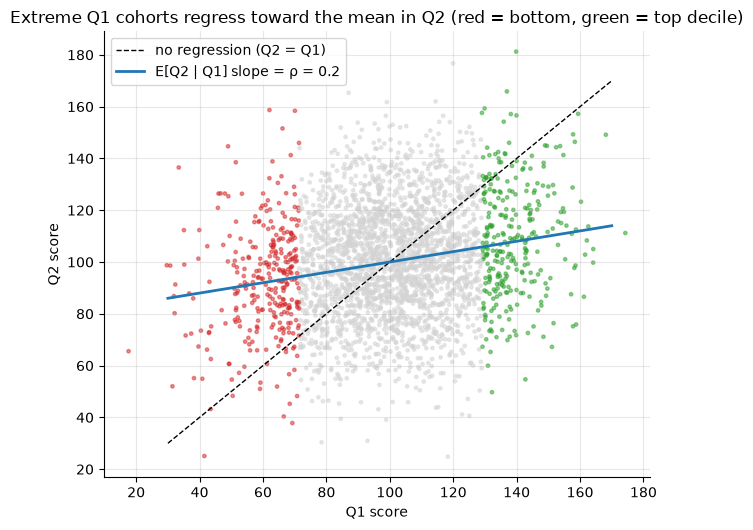

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
idx = rng.choice(n_reps_emp, 3000, replace=False)
colors = np.where(bottom[idx], "tab:red", np.where(top[idx], "tab:green", "lightgray"))
ax.scatter(q1[idx], q2[idx], s=6, c=colors, alpha=0.5)
xs = np.array([30, 170])
ax.plot(xs, xs, "k--", lw=1, label="no regression (Q2 = Q1)")
ax.plot(xs, mu + rho * (xs - mu), color="tab:blue", lw=2,
        label=f"E[Q2 | Q1] slope = ρ = {rho:.1f}")
ax.set_xlabel("Q1 score"); ax.set_ylabel("Q2 score")
ax.set_title("Extreme Q1 cohorts regress toward the mean in Q2 (red = bottom, green = top decile)")
ax.legend()
plt.show()

The bottom decile "improves" by ~31 points (over +50% relative) and the top decile
"declines" by a symmetric amount — both exactly at the reliability-formula prediction. Any
before/after analysis on a cohort *selected for an extreme measurement* is contaminated by
this artifact, and the size of the artifact grows as measurement reliability shrinks.

### The fix: randomize *within* the extreme cohort

Regression to the mean hits treated and control units identically if both are selected the
same way. So: select your bottom decile, then randomize coaching within it. Below, coaching
now has a **true effect of +5 points**:

In [8]:
bottom_idx = np.flatnonzero(bottom)
coached = np.zeros(n_reps_emp, dtype=bool)
coached[rng.permutation(bottom_idx)[: bottom_idx.size // 2]] = True
true_coaching_effect = 5.0
q2_obs = q2 + true_coaching_effect * coached

naive = q2_obs[coached].mean() - q1[coached].mean()
rct = q2_obs[coached].mean() - q2_obs[bottom & ~coached].mean()
se_rct = np.sqrt(q2_obs[coached].var(ddof=1) / coached.sum() +
                 q2_obs[bottom & ~coached].var(ddof=1) / (bottom & ~coached).sum())
print(f"true coaching effect:                        +{true_coaching_effect:.1f} points")
print(f"naive before/after on coached reps:          {naive:+.1f} points  <-- mostly artifact")
print(f"randomized comparison within bottom decile:  {rct:+.1f} ± {1.96*se_rct:.1f} points")

true coaching effect:                        +5.0 points
naive before/after on coached reps:          +35.7 points  <-- mostly artifact
randomized comparison within bottom decile:  +4.3 ± 1.9 points


**Where this trap bites in practice**

- *Targeting extreme cohorts*: win-back campaigns aimed at users with a bad week, retention
  programs for "at-risk" accounts flagged on one noisy score, coaching for the worst stores /
  agents / drivers. All will "work" in a before/after readout.
- *Ops league tables*: this quarter's worst-performing warehouse improves next quarter and
  the intervention du jour takes credit; the best regresses and gets a root-cause review.
- *Sequels and repeats*: "sophomore slump," fund managers topping the charts one year and
  mean-reverting the next (more in
  [../09_finance_and_operations/02_returns_risk.ipynb](../09_finance_and_operations/02_returns_risk.ipynb)).
- *Any pre/post with selection on the pre*. If randomization is truly impossible, you need
  a control selected by the *same rule* (regression discontinuity around the eligibility
  cutoff is the principled version — see
  [../03_causal_inference/04_iv_rdd.ipynb](../03_causal_inference/04_iv_rdd.ipynb)), or you
  must shrink the baseline with the reliability formula and defend $\rho$.

## 3. Multiple testing: an A/A experiment, 20 metrics, 100 segments

**Scenario.** A perfectly null "experiment": users randomly split A vs A, no treatment at
all. The dashboard shows 20 metrics, each sliceable by 100 segments
(4 platforms × 5 countries × 5 tenure bands). An eager analyst scans everything: 2,000
t-tests on pure noise.

In [9]:
n_users = 40_000
platforms = ["iOS", "Android", "Web", "mWeb"]
countries = ["US", "UK", "DE", "IN", "BR"]
tenures = ["new", "1-3m", "3-12m", "1-2y", "2y+"]
segment_names = [f"{p}·{c}·{t}" for p in platforms for c in countries for t in tenures]
metric_names = [
    "sessions", "conversion", "revenue", "aov", "items_per_order", "search_rate",
    "add_to_cart", "checkout_starts", "support_tickets", "page_load_p50",
    "dau_days", "session_length", "bounce_rate", "refund_rate", "coupon_use",
    "wishlist_adds", "reviews_left", "push_optins", "share_rate", "repeat_rate",
]
n_segments, n_metrics = len(segment_names), len(metric_names)

arm = rng.integers(0, 2, n_users)                      # A/A: label is meaningless
segment = rng.integers(0, n_segments, n_users)
metrics = rng.normal(0, 1, size=(n_users, n_metrics))  # pure noise, no effects anywhere

pvals = np.empty((n_segments, n_metrics))
for s in range(n_segments):
    in_s = segment == s
    a = metrics[in_s & (arm == 0)]
    b = metrics[in_s & (arm == 1)]
    pvals[s] = stats.ttest_ind(a, b, axis=0, equal_var=False).pvalue

n_sig = (pvals < 0.05).sum()
print(f"tests run: {pvals.size}   significant at p<0.05: {n_sig}   "
      f"(expected under global null: {0.05 * pvals.size:.0f})")

flat = pd.DataFrame({
    "segment": np.repeat(segment_names, n_metrics),
    "metric": np.tile(metric_names, n_segments),
    "p": pvals.ravel(),
}).sort_values("p")
print("\nthe 8 most 'significant' findings — every one is noise, "
      "and every one suggests a story:")
print(flat.head(8).to_string(index=False))

tests run: 2000   significant at p<0.05: 96   (expected under global null: 100)

the 8 most 'significant' findings — every one is noise, and every one suggests a story:
     segment          metric      p
 iOS·DE·1-3m        dau_days 0.0011
 Web·IN·1-3m     repeat_rate 0.0018
 Web·BR·1-3m        sessions 0.0019
mWeb·DE·1-2y     add_to_cart 0.0026
 mWeb·BR·new checkout_starts 0.0030
  iOS·IN·new   page_load_p50 0.0042
mWeb·IN·1-3m     add_to_cart 0.0042
  Web·DE·new     search_rate 0.0048


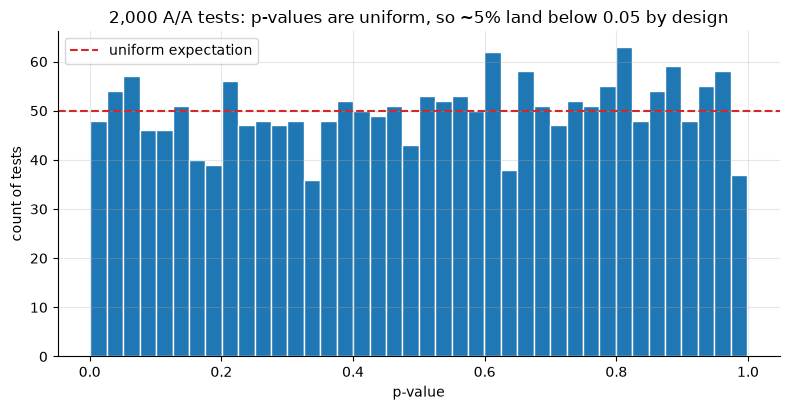

In [10]:
fig, ax = plt.subplots()
ax.hist(pvals.ravel(), bins=40, color="tab:blue", edgecolor="white")
ax.axhline(pvals.size / 40, color="tab:red", ls="--", label="uniform expectation")
ax.set_xlabel("p-value"); ax.set_ylabel("count of tests")
ax.set_title("2,000 A/A tests: p-values are uniform, so ~5% land below 0.05 by design")
ax.legend()
plt.show()

Roughly a hundred "discoveries," each with a plausible narrative attached ("revenue is up
for Android in India among tenured users!"). The family-wise error rate — the probability
of **at least one** false positive among $m$ independent tests — is
$\text{FWER} = 1 - (1-\alpha)^m$: already 64% at $m=20$, and effectively 1 at dashboard
scale. Real metrics are positively correlated, which pulls the FWER below the independent
curve but nowhere near safety:

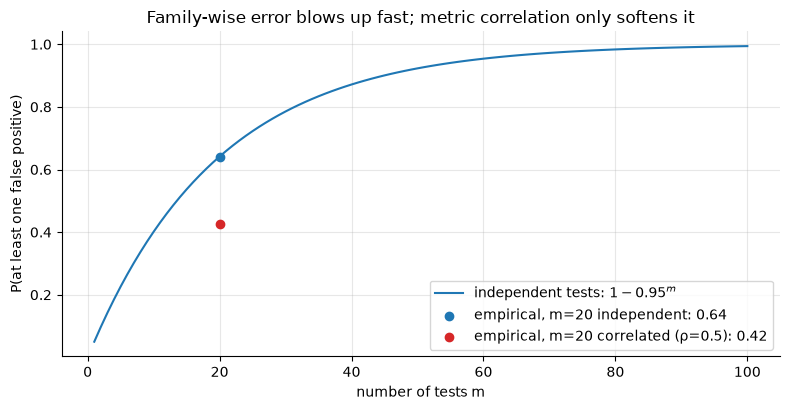

In [11]:
m_grid = np.arange(1, 101)
fig, ax = plt.subplots()
ax.plot(m_grid, 1 - 0.95**m_grid, color="tab:blue", label="independent tests: $1-0.95^m$")

n_fwer_reps, m20 = 20_000, 20
z_ind = rng.normal(size=(n_fwer_reps, m20))
cov = np.full((m20, m20), 0.5); np.fill_diagonal(cov, 1.0)
z_corr = rng.normal(size=(n_fwer_reps, m20)) @ np.linalg.cholesky(cov).T
fwer_ind = (np.abs(z_ind) > 1.96).any(axis=1).mean()
fwer_corr = (np.abs(z_corr) > 1.96).any(axis=1).mean()
ax.scatter([20], [fwer_ind], zorder=5, color="tab:blue",
           label=f"empirical, m=20 independent: {fwer_ind:.2f}")
ax.scatter([20], [fwer_corr], zorder=5, color="tab:red",
           label=f"empirical, m=20 correlated (ρ=0.5): {fwer_corr:.2f}")
ax.set_xlabel("number of tests m"); ax.set_ylabel("P(at least one false positive)")
ax.set_title("Family-wise error blows up fast; metric correlation only softens it")
ax.legend()
plt.show()

### Bonferroni, Holm, Benjamini–Hochberg: mechanics and what they buy you

All three operate on the sorted p-values $p_{(1)} \le \dots \le p_{(m)}$; they differ in
the error rate they control:

- **Bonferroni** (FWER): reject $p_i \le \alpha/m$. One-shot, valid under *any* dependence,
  brutal on power at large $m$.
- **Holm** (FWER): step-down — reject $p_{(i)}$ while $p_{(i)} \le \alpha/(m-i+1)$, stop at
  the first failure. **Uniformly more powerful than Bonferroni with the exact same
  assumptions** — there is no scenario where Bonferroni is preferable, so "Bonferroni vs
  Holm" is not actually a trade-off.
- **Benjamini–Hochberg** (FDR): step-up — find the *largest* $k$ with
  $p_{(k)} \le \frac{k}{m}q$ and reject $p_{(1)},\dots,p_{(k)}$. Controls the *expected
  fraction of discoveries that are false* at $q$, not the chance of any single mistake.
  Exact under independence and positive dependence (PRDS); the Benjamini–Yekutieli variant
  handles arbitrary dependence at a large power cost.

The trade-off only shows up with true effects in the mix. Below: 2,000 tests, 100 of which
carry a real effect (z-shift 3.5), averaged over 200 replications:

In [12]:
def evaluate_procedures(m=2000, m_true=100, shift=3.5, alpha=0.05, n_reps=200):
    truth = np.zeros(m, dtype=bool); truth[:m_true] = True
    acc = {meth: np.zeros(3) for meth in ["bonferroni", "holm", "fdr_bh"]}
    acc["uncorrected"] = np.zeros(3)
    for _ in range(n_reps):
        z = rng.normal(0, 1, m) + shift * truth
        p = 2 * stats.norm.sf(np.abs(z))
        for meth in ["bonferroni", "holm", "fdr_bh"]:
            rej = multipletests(p, alpha=alpha, method=meth)[0]
            acc[meth] += [rej.sum(), (rej & ~truth).sum(), (rej & truth).sum()]
        rej = p < alpha
        acc["uncorrected"] += [rej.sum(), (rej & ~truth).sum(), (rej & truth).sum()]
    rows = []
    for meth, (n_rej, n_false, n_true_disc) in acc.items():
        rows.append({
            "procedure": meth,
            "avg discoveries": n_rej / n_reps,
            "avg false discoveries": n_false / n_reps,
            "realized FDR": n_false / max(n_rej, 1),
            "power (share of 100 real effects found)": n_true_disc / (n_reps * m_true),
        })
    return pd.DataFrame(rows).set_index("procedure")

proc_df = evaluate_procedures()
print("2,000 tests, 100 real effects (z-shift 3.5), alpha = q = 0.05, 200 replications:\n")
print(proc_df.round(3))

2,000 tests, 100 real effects (z-shift 3.5), alpha = q = 0.05, 200 replications:

             avg discoveries  avg false discoveries  realized FDR  \
procedure                                                           
bonferroni            23.865                  0.035         0.001   
holm                  23.920                  0.035         0.001   
fdr_bh                66.330                  3.270         0.049   
uncorrected          187.055                 93.560         0.500   

             power (share of 100 real effects found)  
procedure                                             
bonferroni                                     0.238  
holm                                           0.239  
fdr_bh                                         0.631  
uncorrected                                    0.935  


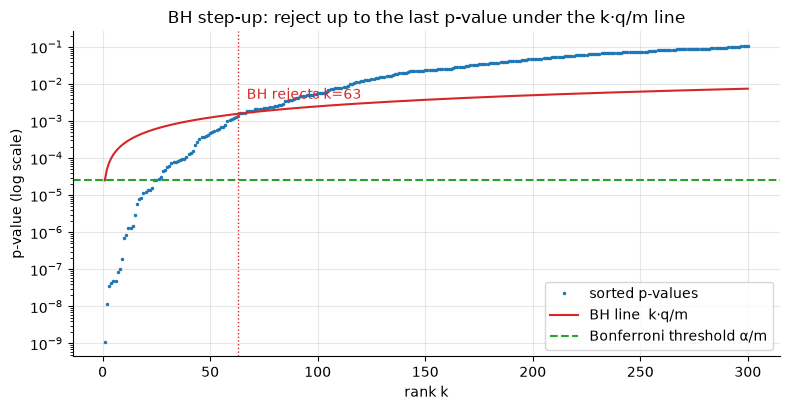

In [13]:
# One replication, zoomed to the smallest 300 p-values, to see the BH step-up geometry.
m, m_true, shift, q_lvl = 2000, 100, 3.5, 0.05
truth = np.zeros(m, dtype=bool); truth[:m_true] = True
z = rng.normal(0, 1, m) + shift * truth
p_sorted = np.sort(2 * stats.norm.sf(np.abs(z)))
k_grid = np.arange(1, m + 1)
bh_line = k_grid * q_lvl / m
k_bh = np.max(np.where(p_sorted <= bh_line)[0]) + 1

fig, ax = plt.subplots()
show = 300
ax.plot(k_grid[:show], p_sorted[:show], ".", ms=3, color="tab:blue", label="sorted p-values")
ax.plot(k_grid[:show], bh_line[:show], color="tab:red", label="BH line  k·q/m")
ax.axhline(q_lvl / m, color="tab:green", ls="--", label="Bonferroni threshold α/m")
ax.axvline(k_bh, color="tab:red", ls=":", lw=1)
ax.annotate(f"BH rejects k={k_bh}", (k_bh + 4, 0.004), color="tab:red")
ax.set_yscale("log")
ax.set_xlabel("rank k"); ax.set_ylabel("p-value (log scale)")
ax.set_title("BH step-up: reject up to the last p-value under the k·q/m line")
ax.legend(loc="lower right")
plt.show()

Holm nudges past Bonferroni; BH roughly **triples the power** here (0.63 vs 0.24) while
keeping the realized false-discovery *fraction* near 5%. The price: with BH some discoveries are wrong
by design — you are buying recall with a controlled contamination rate.

**Which correction fits which analytics job** — pick the error rate that matches the cost
structure of the decision, then the best procedure for that rate:

- **One pre-registered primary metric deciding a launch** → no correction needed; the
  family is one test. (Guardrails get their own, usually one-sided, tests.)
- **A handful of co-primary decisions where any single false claim is expensive**
  (a public claim, a medical/regulatory context, shipping to 100M users) → FWER, i.e.
  **Holm** (never plain Bonferroni — Holm strictly dominates it).
- **Exploratory scans to generate hypotheses** — the metric×segment sweep above, feature
  screens, weekly "what moved" reports → **BH at q = 0.05–0.20**. A dashboard scan does not
  need "no mistakes ever"; it needs "most of what we chase is real."
- **Screens at genomics/finance scale** ($m$ in the 10⁴–10⁶ range) → FDR is the only game
  in town; FWER control leaves you with nothing.

And the correction is a band-aid: the structural fixes are pre-registering a small family,
and shrinking segment estimates with hierarchical models
([../06_bayesian_methods/03_hierarchical_models.ipynb](../06_bayesian_methods/03_hierarchical_models.ipynb))
rather than testing each segment in isolation.

## 4. p-hacking and the garden of forking paths

Corrections assume you can *count* your tests. The nastier problem is procedures whose test
count is implicit — analysis choices made after seeing data. Two workhorses of accidental
p-hacking:

1. **Optional stopping**: check the p-value as data accrues, stop when it dips below 0.05.
   Under H0 the z-statistic is a random walk; given enough looks it *will* wander across
   ±1.96.
2. **Subgroup mining**: the overall effect is flat, so slice by platform/country/cohort
   until a slice is significant ("the effect is concentrated in Android · new users").

Neither requires bad faith — each look and each slice feels like diligence. Gelman's
"garden of forking paths": the multiplicity is over analyses you *would have* run had the
data looked different, which no correction applied afterward can count. Simulation: an A/A
test (true effect exactly zero), peeked at 20 times (every 500 users/arm up to 10,000/arm),
and sliced into 30 subgroups at the end.

In [14]:
n_paths, n_looks, chunk = 4_000, 20, 500

# Peeking: z-statistic path via chunk sums (mean-difference test, sigma known = 1)
inc_a = rng.normal(0, np.sqrt(chunk), (n_paths, n_looks))
inc_b = rng.normal(0, np.sqrt(chunk), (n_paths, n_looks))
n_k = chunk * np.arange(1, n_looks + 1)
z_path = (inc_a.cumsum(1) - inc_b.cumsum(1)) / n_k / np.sqrt(2.0 / n_k)
crossed = np.abs(z_path) > 1.96

looks_grid = [1, 2, 5, 10, 20]
fp_by_looks = {k: crossed[:, :k].any(axis=1).mean() for k in looks_grid}

# Subgroup mining at the final look: 30 (approximately independent) subgroup z-stats
n_subgroups = 30
z_sub = rng.normal(size=(n_paths, n_subgroups))
fp_subgroups = (np.abs(z_sub) > 1.96).any(axis=1).mean()
fp_either = (crossed.any(axis=1) | (np.abs(z_sub) > 1.96).any(axis=1)).mean()

print("False-positive rate on a TRUE NULL (A/A), nominal alpha = 0.05:\n")
for k in looks_grid:
    print(f"  peeking, first {k:>2} look(s): {fp_by_looks[k]:.3f}")
print(f"  30 subgroups at final look:  {fp_subgroups:.3f}   "
      f"(theory 1-0.95^30 = {1 - 0.95**30:.3f})")
print(f"  peeking OR subgroup hit:     {fp_either:.3f}")

False-positive rate on a TRUE NULL (A/A), nominal alpha = 0.05:

  peeking, first  1 look(s): 0.048
  peeking, first  2 look(s): 0.081
  peeking, first  5 look(s): 0.136
  peeking, first 10 look(s): 0.195
  peeking, first 20 look(s): 0.249
  30 subgroups at final look:  0.797   (theory 1-0.95^30 = 0.785)
  peeking OR subgroup hit:     0.851


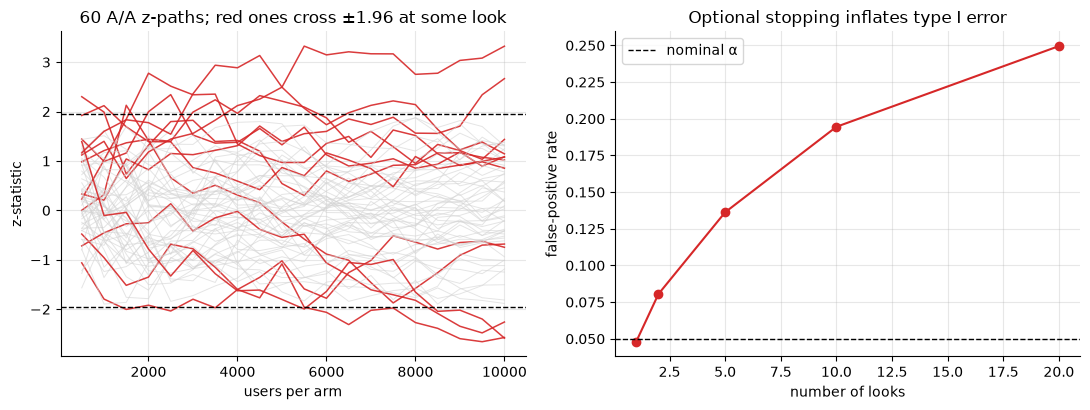

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
for i in range(60):
    hit = crossed[i].any()
    ax.plot(n_k, z_path[i], color="tab:red" if hit else "lightgray",
            lw=1.1 if hit else 0.7, alpha=0.9 if hit else 0.6)
ax.axhline(1.96, color="k", ls="--", lw=1); ax.axhline(-1.96, color="k", ls="--", lw=1)
ax.set_xlabel("users per arm"); ax.set_ylabel("z-statistic")
ax.set_title("60 A/A z-paths; red ones cross ±1.96 at some look")

ax = axes[1]
ax.plot(looks_grid, [fp_by_looks[k] for k in looks_grid], "o-", color="tab:red")
ax.axhline(0.05, color="k", ls="--", lw=1, label="nominal α")
ax.set_xlabel("number of looks"); ax.set_ylabel("false-positive rate")
ax.set_title("Optional stopping inflates type I error")
ax.legend()
plt.show()

One legitimate look costs the advertised 5%. Twenty looks push it to ~25%, subgroup mining
alone reaches ~80%, and an analyst allowed to do either finds a "significant result" in
about **85% of null experiments** — call it five out of six. Other forks compound further: outlier rules
chosen after seeing arms, metric definition tweaks, covariate sets, "extend the test one
more week."

What actually works:

- **Pre-register the analysis**: primary metric, sample size, stopping rule, segment list,
  exclusion rules — before launch. This is cheap (a template in the experiment tool), and it
  converts forking paths into a countable family.
- **Peeking is fine if designed for**: group-sequential bounds (O'Brien–Fleming), alpha
  spending, or always-valid/sequential p-values — the topic of
  [../02_ab_testing/04_peeking_sequential.ipynb](../02_ab_testing/04_peeking_sequential.ipynb).
- **Mined subgroups are hypotheses, not findings**: they get FDR treatment in the scan and a
  *fresh confirmatory experiment* before anyone acts (Pitfall 2 below shows why "validating"
  on the same data is circular).

## 5. Winner's curse: significant estimates are exaggerated estimates (Type M error)

Condition on $|\hat\delta| > 1.96\,\text{se}$ and you have truncated the sampling
distribution: only the lucky draws survive. At low power the truncation is savage — the
*only* way a small true effect clears the significance bar is by being overestimated.
Gelman & Carlin call the factor $\mathbb{E}\big[|\hat\delta| \,\big|\, \text{significant}\big] / \delta$
the **exaggeration ratio (Type M)**; the sign-flip probability among significant results is
**Type S**.

In [16]:
def type_m_s(power, delta=1.0, n_sims=200_000):
    """Exaggeration ratio and sign-error rate for a two-sided z-test at given power."""
    se = delta / (1.96 + stats.norm.ppf(power))     # solves power = P(reject | delta)
    est = rng.normal(delta, se, n_sims)
    sig = np.abs(est) > 1.96 * se
    exaggeration = np.abs(est[sig]).mean() / delta
    type_s = (est[sig] < 0).mean()
    return exaggeration, type_s, sig.mean()

rows = []
for pw in [0.06, 0.10, 0.20, 0.30, 0.50, 0.80, 0.95]:
    ex, ts, emp_pw = type_m_s(pw)
    rows.append({"design power": pw, "empirical power": emp_pw,
                 "exaggeration ratio E[|est| | sig]/true": ex,
                 "Type S (wrong sign | sig)": ts})
tm = pd.DataFrame(rows).set_index("design power")
print("Winner's curse by power (true effect fixed, se varied; 200k sims per row):\n")
print(tm.round(3))

Winner's curse by power (true effect fixed, se varied; 200k sims per row):

              empirical power  exaggeration ratio E[|est| | sig]/true  \
design power                                                            
0.06                    0.069                                   5.878   
0.10                    0.103                                   3.580   
0.20                    0.200                                   2.250   
0.30                    0.303                                   1.806   
0.50                    0.501                                   1.407   
0.80                    0.801                                   1.125   
0.95                    0.949                                   1.031   

              Type S (wrong sign | sig)  
design power                             
0.06                              0.129  
0.10                              0.039  
0.20                              0.005  
0.30                              0.001  
0.50          

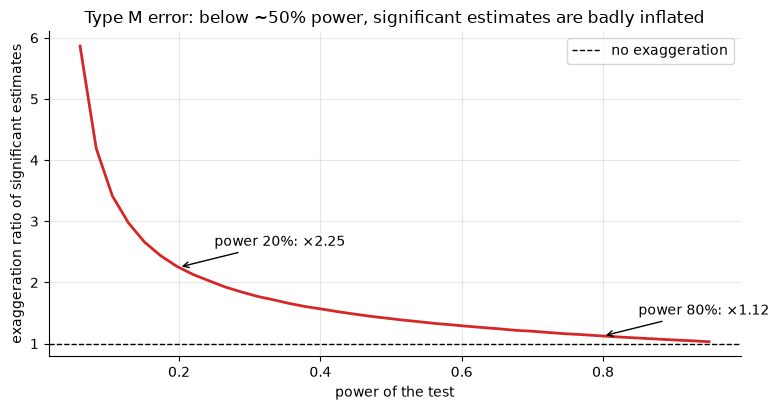

In [17]:
pw_grid = np.linspace(0.06, 0.95, 40)
curve = [type_m_s(p, n_sims=60_000)[0] for p in pw_grid]
fig, ax = plt.subplots()
ax.plot(pw_grid, curve, color="tab:red", lw=2)
ax.axhline(1.0, color="k", ls="--", lw=1, label="no exaggeration")
for p_mark in [0.2, 0.8]:
    ex_mark = type_m_s(p_mark, n_sims=100_000)[0]
    ax.annotate(f"power {p_mark:.0%}: ×{ex_mark:.2f}", (p_mark, ex_mark),
                xytext=(p_mark + 0.05, ex_mark + 0.35),
                arrowprops=dict(arrowstyle="->", lw=1))
ax.set_xlabel("power of the test"); ax.set_ylabel("exaggeration ratio of significant estimates")
ax.set_title("Type M error: below ~50% power, significant estimates are badly inflated")
ax.legend()
plt.show()

At 20% power — completely typical for a secondary metric or a per-segment estimate —
significant estimates run ~2.2× the truth, and at near-null power the machine only outputs
fantasy (~6× with a nontrivial chance the sign is wrong). This is the clean answer to
"why do effects shrink when we re-run the winner?": the rerun is an unbiased draw; the
original was a *selected* draw. Regression to the mean and the winner's curse are the same
phenomenon — selection on a noisy maximum — wearing different clothes.

### What it does to a year of experiment wins

A team runs 40 tests/year. Most ideas do nothing; some help a little; a few hurt. Ship
whatever is significantly positive, add up the dashboard-claimed lifts, compare to reality:

In [18]:
n_years, tests_per_year = 1_000, 40
se_exp = 0.008                                   # se of estimated relative lift per test
is_real = rng.random((n_years, tests_per_year)) < 0.4
true_lift = np.where(is_real, rng.normal(0.010, 0.010, (n_years, tests_per_year)), 0.0)
est_lift = true_lift + rng.normal(0, se_exp, (n_years, tests_per_year))
shipped = est_lift > 1.96 * se_exp               # ship if significantly positive

claimed = np.where(shipped, est_lift, 0).sum(axis=1)
realized = np.where(shipped, true_lift, 0).sum(axis=1)
print(f"avg experiments shipped per year:      {shipped.sum(axis=1).mean():.1f} of "
      f"{tests_per_year}")
print(f"avg claimed total lift (sum of estimates): {claimed.mean():+.1%}")
print(f"avg realized total lift (sum of truths):   {realized.mean():+.1%}")
print(f"claimed / realized:                        {claimed.mean() / realized.mean():.2f}x")

avg experiments shipped per year:      5.8 of 40
avg claimed total lift (sum of estimates): +13.7%
avg realized total lift (sum of truths):   +9.8%
claimed / realized:                        1.40x


The roadmap deck promises ~40% more than actually materializes — and with lower-powered
tests than these the gap widens fast. This is why mature experiment
platforms report *shrunken* estimates (empirical-Bayes toward the platform-wide effect
distribution), run **holdback groups** to measure cumulative realized impact, and treat
"sum of significant lifts" as a vanity number. Fixes, in order of leverage: power up the
tests you care about ([../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb)),
shrink estimates before planning on them, and replicate before making irreversible bets.

## 6. Survivorship and selection bias — and Berkson's collider

### Surveying only the users who stayed

**Scenario.** A cohort of 30,000 new users; each has a latent satisfaction (mean 6.0/10).
Monthly churn depends strongly on satisfaction. Six months in, the team surveys *active*
users ("our NPS keeps improving!"). Nobody's satisfaction ever changes in this simulation —
only the composition of who is left:

In [19]:
n_cohort = 30_000
satisfaction = np.clip(rng.normal(6.0, 1.5, n_cohort), 0, 10)
p_churn_monthly = expit(-(satisfaction - 4.0))     # sat 4 -> 50%/mo, sat 6 -> 12%, sat 8 -> 2%

alive = np.ones(n_cohort, dtype=bool)
history = [{"month": 0, "retention": 1.0, "survivor mean satisfaction": satisfaction.mean()}]
for month in range(1, 7):
    alive &= rng.random(n_cohort) >= p_churn_monthly
    history.append({"month": month, "retention": alive.mean(),
                    "survivor mean satisfaction": satisfaction[alive].mean()})
surv = pd.DataFrame(history).set_index("month")
print(surv.round(3))
print(f"\ntrue cohort mean satisfaction (never changed): {satisfaction.mean():.2f}")
print(f"mean satisfaction of the churned:              {satisfaction[~alive].mean():.2f}")
print(f"month-6 survey of active users reads:          {satisfaction[alive].mean():.2f}")

       retention  survivor mean satisfaction
month                                       
0          1.000                       5.995
1          0.811                       6.321
2          0.694                       6.532
3          0.615                       6.680
4          0.551                       6.802
5          0.500                       6.903
6          0.461                       6.983

true cohort mean satisfaction (never changed): 5.99
mean satisfaction of the churned:              5.15
month-6 survey of active users reads:          6.98


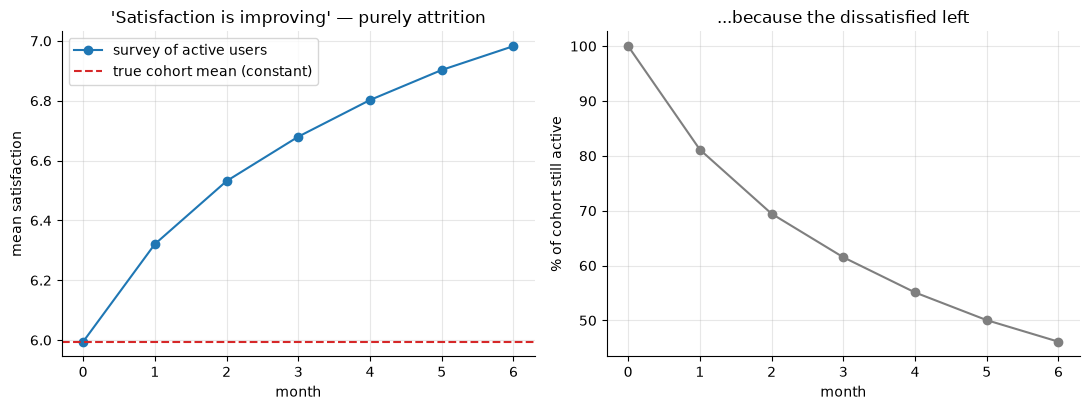

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(surv.index, surv["survivor mean satisfaction"], "o-", color="tab:blue",
             label="survey of active users")
axes[0].axhline(satisfaction.mean(), color="tab:red", ls="--",
                label="true cohort mean (constant)")
axes[0].set_xlabel("month"); axes[0].set_ylabel("mean satisfaction")
axes[0].set_title("'Satisfaction is improving' — purely attrition")
axes[0].legend()
axes[1].plot(surv.index, surv["retention"] * 100, "o-", color="tab:gray")
axes[1].set_xlabel("month"); axes[1].set_ylabel("% of cohort still active")
axes[1].set_title("...because the dissatisfied left")
plt.show()

Every readout that conditions on survival has this shape: app-store ratings (uninstallers
don't rate), "power users love feature X" (feature X users are your most engaged anyway),
churned-user exit surveys with 4% response, backtests on today's index constituents
(delisted losers excluded — see
[../09_finance_and_operations/02_returns_risk.ipynb](../09_finance_and_operations/02_returns_risk.ipynb)),
and the WWII bomber armor classic. The question to ask of any dataset: **who had to still
be around — or choose to respond — for this row to exist?** If the answer correlates with
the outcome, estimate the selection or don't trust the number. Churn itself is modeled
properly in [../08_product_analytics/02_churn_survival.ipynb](../08_product_analytics/02_churn_survival.ipynb).

### Berkson's paradox: selection creates correlation (the collider)

**Scenario.** VCs fund startups when *team quality + idea quality* clears a bar (top 10% of
the applicant pool). In the population the two are essentially independent. Funding is a
**collider**: caused by both. Condition on it — e.g. run your analysis "among our portfolio
companies" — and a negative correlation appears from nowhere: a funded startup with a
mediocre idea *must* have had a great team to clear the bar, and vice versa.

corr(team, idea) in the whole population: -0.003
corr(team, idea) among FUNDED startups:   -0.723


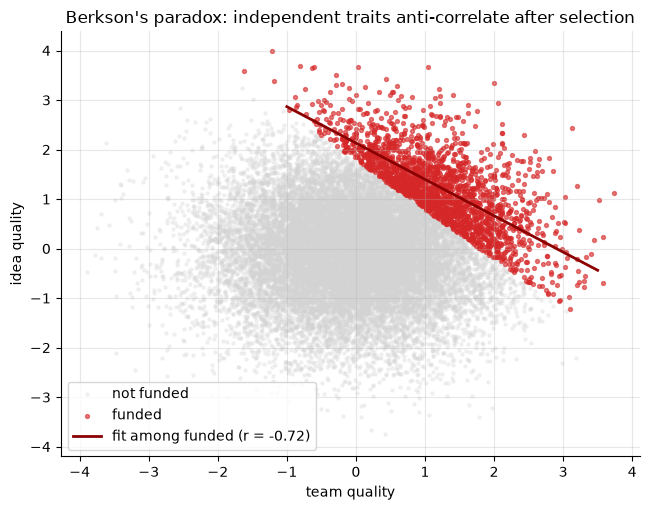

In [21]:
n_startups = 20_000
team = rng.normal(0, 1, n_startups)
idea = rng.normal(0, 1, n_startups)
funded = (team + idea) > np.quantile(team + idea, 0.90)

r_all = stats.pearsonr(team, idea)
r_funded = stats.pearsonr(team[funded], idea[funded])
print(f"corr(team, idea) in the whole population: {r_all.statistic:+.3f}")
print(f"corr(team, idea) among FUNDED startups:   {r_funded.statistic:+.3f}")

fig, ax = plt.subplots(figsize=(6.6, 5.2))
ax.scatter(team[~funded], idea[~funded], s=5, alpha=0.25, color="lightgray",
           label="not funded")
ax.scatter(team[funded], idea[funded], s=8, alpha=0.6, color="tab:red", label="funded")
sl, ic = np.polyfit(team[funded], idea[funded], 1)
xs = np.linspace(-1, 3.5, 10)
ax.plot(xs, ic + sl * xs, color="darkred", lw=2,
        label=f"fit among funded (r = {r_funded.statistic:+.2f})")
ax.set_xlabel("team quality"); ax.set_ylabel("idea quality")
ax.set_title("Berkson's paradox: independent traits anti-correlate after selection")
ax.legend(loc="lower left")
plt.show()

The correlation among the funded is strongly negative (~−0.7) with zero causal relationship
anywhere. The same geometry produces:

- *Hiring*: among people you hired, interview performance anti-correlates with resume
  strength — so "our interviews are anti-predictive!" panics are often just this.
- *Product*: among users who converted, price sensitivity and feature need look
  negatively related; among escalated tickets, severity anti-correlates with customer size.
- *Content*: among viral posts, production quality anti-correlates with topicality.
- The dating cliché ("attractive people are jerks") — conditioning on "I dated them."

The general lesson unifies this whole notebook section: **conditioning on a variable caused
by two others induces dependence between them.** Filtering a dataset *is* conditioning.
Every `WHERE` clause is a potential collider. The DAG machinery for spotting these before
they bite is in
[../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb).

## 7. Goodhart's law: when a measure becomes a target

> "When a measure becomes a target, it ceases to be a good measure."

Everything above is about *reading* metrics wrong; Goodhart is about metrics changing under
your feet *because* people optimize them. A metric is always a proxy for the thing you
care about, and optimization pressure finds the gap between proxy and target:

- **Support**: target *average handle time* → agents transfer or drop hard calls; target
  *tickets closed* → close-then-reopen; target *CSAT response rate* → agents beg for 5s and
  only survey happy customers (selection bias, weaponized).
- **Recommenders**: target CTR → clickbait thumbnails win; watch-time → autoplay
  rabbit holes; engagement → outrage. The proxy–value correlation that justified the metric
  was measured *before* the optimizer started exploiting it.
- **Sales**: quarterly quota → deals pulled forward / discount stuffing in week 13, revenue
  borrowed from next quarter.
- **Engineering**: bug-count targets → ticket splitting; test-coverage targets → assertion-
  free tests; velocity targets → point inflation.
- **Models**: optimizing a fraud model's alert *volume* instead of caught-fraud value;
  teams tuning to a leaderboard metric until it decouples from production value (the
  offline/online gap — see [../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb)).

Two mechanisms are worth naming in interviews: **gaming** (behavior shifts to exploit the
measurement gap) and **selection pressure** (even with no bad intent, choosing
people/projects/models by a noisy proxy selects for proxy-overfit — the winner's curse of
Section 5 acting on an organization). Mitigations that hold up in practice:

- Pair every target metric with **counter-metrics/guardrails** that get expensive when the
  target is gamed (handle time × resolution rate × reopen rate).
- Keep a **long-term holdout** exempt from optimization to measure drift between proxy and
  true value (the metric-design analog of Section 5's holdback group).
- Rotate and audit metrics; assume any target older than a few quarters is partially gamed.
- Prefer targets close to value (retained revenue) over upstream proxies (clicks) when
  measurement latency allows. Metric design is treated fully in
  [../08_product_analytics/01_metrics_and_growth.ipynb](../08_product_analytics/01_metrics_and_growth.ipynb).

## 8. Pitfalls: the mistaken fixes

The traps above are famous; the *fixes people improvise* have their own failure modes.

### Pitfall 1 — correcting the pre-registered primary for the whole exploratory family

After learning about multiple testing, teams sometimes Bonferroni **everything in the
experiment readout** — including the single pre-registered primary metric — over the 2,000
exploratory cells. The correction family is defined by the *decision*, not by everything the
tool happens to compute. Cost, at a true lift powered at 80% for a single test:

In [22]:
n_sims_p1, m_family = 100_000, 2000
z_primary = rng.normal(2.8, 1, n_sims_p1)         # delta/se = 2.8  ->  ~80% power alone
power_alone = (np.abs(z_primary) > stats.norm.ppf(1 - 0.05 / 2)).mean()
power_bonf = (np.abs(z_primary) > stats.norm.ppf(1 - 0.05 / (2 * m_family))).mean()
print(f"power of the primary test, own alpha=0.05:              {power_alone:.2f}")
print(f"power if Bonferroni'd across the m=2000 exploratory scan: {power_bonf:.2f}")

power of the primary test, own alpha=0.05:              0.80
power if Bonferroni'd across the m=2000 exploratory scan: 0.08


The same experiment drops from an 80% detection rate to ~8% — you paid for a powered
experiment and then threw the power away. The right structure: **the primary metric is its
own family** (α = 0.05, no correction); guardrails form a small FWER family; the
exploratory scan gets BH *separately*. One readout, three explicitly declared families.

### Pitfall 2 — "validating" a mined subgroup on the same data

The scan finds "significant for Android new users." Someone "confirms" it by re-running the
test on that subgroup — on the *same data*. That re-test is the same arithmetic and passes
by construction. The honest check is fresh data:

In [23]:
n_mine, n_sub = 4_000, 30
z1 = rng.normal(size=(n_mine, n_sub))      # original experiment (pure null)
z2 = rng.normal(size=(n_mine, n_sub))      # independent replication of every subgroup

found = np.abs(z1).max(axis=1) > 1.96      # experiments where mining "found something"
best = np.abs(z1).argmax(axis=1)
r = np.arange(n_mine)
same_data = np.abs(z1[r, best]) > 1.96     # "confirm" on the same data
fresh = (np.abs(z2[r, best]) > 1.96) & (np.sign(z2[r, best]) == np.sign(z1[r, best]))

print(f"null experiments where mining found a significant subgroup: {found.mean():.1%}")
print(f"  ...'confirmed' when re-tested on the SAME data:  {same_data[found].mean():.1%}")
print(f"  ...confirmed on FRESH data (same sign, p<0.05):  {fresh[found].mean():.1%}")
print(f"  mean |z| of the mined subgroup, original run:    {np.abs(z1[r, best])[found].mean():.2f}")
print(f"  mean |z| of that subgroup in replication:        {np.abs(z2[r, best])[found].mean():.2f}")

null experiments where mining found a significant subgroup: 79.0%
  ...'confirmed' when re-tested on the SAME data:  100.0%
  ...confirmed on FRESH data (same sign, p<0.05):  2.4%
  mean |z| of the mined subgroup, original run:    2.47
  mean |z| of that subgroup in replication:        0.79


Same-data "validation" confirms 100% of noise; fresh data confirms ~2%, and the mined
subgroup's |z| collapses from ~2.4 to ~0.8 (about the mean of |N(0,1)|) on replication.
Selection must be paid for with *new* data — or modeled explicitly.

### Pitfall 3 — reporting the best of K arms at face value

No significance filter needed: just running K variants and quoting the best one's estimate
is already selection on noise. Ten null arms against control, conversion 5%:

In [24]:
n_multi, k_arms, n_arm_users, p_base = 3_000, 10, 5_000, 0.05
control = rng.binomial(n_arm_users, p_base, n_multi) / n_arm_users
arms = rng.binomial(n_arm_users, p_base, (n_multi, k_arms)) / n_arm_users
best_lift = arms.max(axis=1) - control          # all arms are identical to control

sd_arm = np.sqrt(p_base * (1 - p_base) / n_arm_users)      # sd of one arm's estimate
se_diff = np.sqrt(2) * sd_arm                              # se of (arm - control)
print(f"true lift of every arm: 0.00 pp")
print(f"mean estimated lift of the BEST of {k_arms} arms: "
      f"{best_lift.mean() * 100:+.2f} pp ({best_lift.mean() / p_base:+.1%} relative)")
print(f"theory: E[max of {k_arms} iid N(0, sd_arm)] = 1.539·sd_arm = "
      f"+{1.539 * sd_arm * 100:.2f} pp   (control noise averages out)")
print(f"best arm 'significant' vs control at one-sided 5%: "
      f"{(best_lift > 1.645 * se_diff).mean():.1%} of null experiments")

true lift of every arm: 0.00 pp
mean estimated lift of the BEST of 10 arms: +0.48 pp (+9.7% relative)
theory: E[max of 10 iid N(0, sd_arm)] = 1.539·sd_arm = +0.47 pp   (control noise averages out)
best arm 'significant' vs control at one-sided 5%: 25.2% of null experiments


The best of ten identical arms shows ~+0.47 pp (+9% relative) on average, and is
"significant" about a quarter of the time — less than the naive $1-0.95^{10}=40\%$ because
all ten comparisons share the same control arm and are therefore positively correlated,
but five times the nominal rate. Multi-arm readouts need either a max-t / Dunnett-style
correction, or estimation machinery built for adaptive selection — bandits and their
post-hoc inference, in
[../06_bayesian_methods/04_bandits_thompson.ipynb](../06_bayesian_methods/04_bandits_thompson.ipynb).

## 9. Interview corner

**Q1. Your A/B test is flat overall but positive in every major segment (or the reverse) —
what do you do?**
First instinct: *this should not happen in a healthy randomized test*, so check the
assignment mechanism — sample-ratio mismatch overall and within segments, ramp timing,
bot/dedup filters. If randomization is intact, ask whether the segmenting variable is
pre-treatment (confounder → segment/standardize) or post-treatment (mediator/collider →
aggregate; the segmented view is bias). Never resolve it by "which number looks better";
resolve it with the causal position of the variable. Twyman's law applies: the most
surprising cut is most likely a data problem.

**Q2. Why do most significant effects shrink when re-run?**
Winner's curse / Type M: conditioning on significance selects positively-erred draws; at
20% power significant estimates average ~2.2× truth. The replication is an unbiased draw
from the same distribution — no mystery, no "novelty effect" needed (though those exist
too). Senior extras: quantify with the exaggeration ratio, mention empirical-Bayes
shrinkage using the platform's historical effect distribution, and note the portfolio
consequence (claimed annual lift ran ~1.4× realized even in our moderately-powered
simulation; holdbacks measure the truth).

**Q3. The team ran 40 tests this year and 3 were significant — what do you tell the VP?**
Expected false positives under a global null: 40 × 0.05 = 2 — so 3 significant results
carry little evidence that *any* idea worked. Don't pick winners from this table. Plan:
check the p-value distribution against uniform (excess mass near 0 = real signal); apply BH
across the 40 to prioritize; re-run the survivors as confirmations at proper power; then
fix the pipeline problem — a 5–8% win rate usually means under-powered tests or weak
hypotheses ([../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb)).

**Q4. "We coached the bottom-decile agents and their scores rose 30% — should we scale the
program?"**
Regression to the mean until proven otherwise. Ask for score reliability (test-retest
correlation ρ); expected artifact is (1−ρ) of the selection gap with *zero* treatment
effect. The fix is randomizing within the eligible (bottom-decile) pool — RTM then hits
both arms equally. If the program already ran everywhere, compare against the counterfactual
predicted by ρ, or exploit the eligibility cutoff (RDD). Also flag the incentive version:
any program targeted at extremes will *always* look good in before/after, which is why such
programs never die.

**Q5. "Among our funded startups (enterprise customers / hired candidates), X and Y are
negatively correlated — does X crowd out Y?"**
Collider check first: was the dataset selected on something caused by both X and Y
(funding ≈ team + idea)? If so, the negative correlation is manufactured by selection and
says nothing about the population. Offer the geometric intuition (the selection bar cuts a
diagonal band) and a falsification path: measure X, Y in the *applicant* pool, or model the
selection rule explicitly.

**Q6. Design an experiment-review policy that prevents p-hacking without killing
exploration.**
Separate confirmatory from exploratory *by contract*: (1) pre-registered primary +
guardrails, fixed n or a proper sequential design; (2) exploration encouraged but labeled —
segment scans get BH and feed a hypothesis backlog, never a launch; (3) confirmations of
mined hypotheses run on fresh traffic; (4) platform reports shrunken estimates and runs an
annual holdback to reconcile claimed vs realized lift; (5) all analyses logged (the forking
paths become countable). This is the org-level answer interviewers want, not "use
Bonferroni."

**Q7. When would you use Bonferroni/Holm vs Benjamini–Hochberg?**
Match the error rate to the decision cost: FWER (use Holm — it dominates Bonferroni at
identical assumptions) when any single false claim is expensive and the family is small;
FDR/BH when scanning many hypotheses and a controlled fraction of false leads is
acceptable. Note dependence caveats (BH is fine under positive dependence; BY for
arbitrary), and that the family is defined by the decision, not by the query count.

## 10. Key takeaways

- Simpson's paradox is a *causal* problem: segment when the slicing variable is a
  pre-treatment confounder; aggregate when it's post-treatment (mediator/collider). In a
  randomized test, a Simpson flip usually means broken randomization — check SRM.
- Regression to the mean is fully predictable: $E[Y_2|Y_1] = \mu + \rho(Y_1-\mu)$. Any
  before/after readout on a cohort selected for extreme measurements is contaminated;
  randomize *within* the selected cohort.
- Scanning 20 metrics × 100 segments manufactures ~100 significant results from pure noise.
  FWER $= 1-(1-\alpha)^m$; correlation between metrics softens but doesn't save you.
- Holm strictly dominates Bonferroni. BH controls the false-discovery *fraction* and buys
  large power gains — the right tool for exploratory scans; FWER (Holm) for small families
  of expensive claims; no correction for a single pre-registered primary.
- Optional stopping (~25% FP at 20 peeks) and subgroup mining (~80% FP at 30 slices)
  combine to make "significant somewhere" nearly certain under the null. Pre-register, use
  proper sequential methods, and confirm mined subgroups on fresh data.
- Winner's curse / Type M: at 20% power, significant estimates average ~2.2× the truth;
  summed "shipped wins" claim ~40% more than materializes even at moderate power. Shrink,
  replicate, holdback.
- Survivorship: ask who must still exist (or choose to respond) for a row to appear.
  Berkson: every filter is conditioning; conditioning on a collider creates correlation
  from nothing.
- Goodhart: pair targets with counter-metrics, keep optimization-exempt holdouts, and
  assume old targets are partially gamed.

## 11. Exercises

**Exercise 1 — Standardization weights.** In Section 1 we standardized the checkout
comparison to the *old-flow* device mix. Re-standardize to the *new-flow* mix and to the
pooled (overall) mix. Do the answers differ much here? When would they differ, and what is
the causal-inference name for the distinction?

**Exercise 2 — RTM for the top 5%.** Using the Section 2 population parameters
(μ=100, σ_skill=10, σ_noise=20), predict the expected Q2 score of the **top 5%** of Q1
performers using the reliability formula (you'll need the mean of a truncated normal), then
verify by simulation. How large is the "decline" a naive analyst would attribute to
complacency?

**Exercise 3 — Holm from scratch.** Implement the Holm step-down procedure yourself and
verify it reproduces `multipletests(..., method="holm")` decisions exactly on the 2,000
A/A p-values from Section 3, at α = 0.05 and α = 0.20 (use the flattened `pvals`).

In [25]:
# --- Solution 1 ---
mix_new = checkout.loc[checkout["group"] == "new flow", "device"].value_counts(normalize=True)
mix_pool = checkout["device"].value_counts(normalize=True)
for name, w in [("old-flow mix (ATC-like)", mix_old),
                ("new-flow mix (ATT-like)", mix_new),
                ("pooled mix (ATE-like)", mix_pool)]:
    lift_w = (p_seg["new flow"] * w).sum() / (p_seg["old flow"] * w).sum() - 1
    print(f"standardized to {name:<24}: {lift_w:+.1%}")
# The within-device relative lift is the same (+25%) in both segments by construction, so
# all three weightings agree up to sampling noise. They genuinely diverge when the effect is
# heterogeneous across segments: weighting by the treated mix answers "what did treatment do
# to the treated" (ATT), the control mix answers ATC, the pooled mix ~ ATE. You must name
# the target population before quoting one number.

standardized to old-flow mix (ATC-like) : +23.2%
standardized to new-flow mix (ATT-like) : +24.9%
standardized to pooled mix (ATE-like)   : +23.9%


In [26]:
# --- Solution 2 ---
alpha_top = 0.05
z_cut = stats.norm.ppf(1 - alpha_top)                       # 95th pct of Q1 (standardized)
sigma_q1 = np.sqrt(sigma_skill**2 + sigma_noise**2)
trunc_mean = stats.norm.pdf(z_cut) / alpha_top              # E[Z | Z > z_cut], inverse Mills
q1_top_pred = mu + sigma_q1 * trunc_mean
q2_top_pred = mu + rho * (q1_top_pred - mu)
top5 = q1 >= np.quantile(q1, 1 - alpha_top)
print(f"predicted top-5% Q1 mean: {q1_top_pred:.1f}   simulated: {q1[top5].mean():.1f}")
print(f"predicted their Q2 mean:  {q2_top_pred:.1f}   simulated: {q2[top5].mean():.1f}")
print(f"apparent 'decline' with zero real change: {q2[top5].mean() - q1[top5].mean():+.1f} "
      f"points — complacency not required.")

predicted top-5% Q1 mean: 146.1   simulated: 146.7
predicted their Q2 mean:  109.2   simulated: 108.0
apparent 'decline' with zero real change: -38.8 points — complacency not required.


In [27]:
# --- Solution 3 ---
def holm(p, alpha=0.05):
    """Holm step-down: reject sorted p_(i) while p_(i) <= alpha/(m-i); stop at first failure."""
    p = np.asarray(p)
    m = p.size
    order = np.argsort(p)
    reject = np.zeros(m, dtype=bool)
    for i, j in enumerate(order):                # i = 0-based rank
        if p[j] <= alpha / (m - i):
            reject[j] = True
        else:
            break                                # step-down: stop at first non-rejection
    return reject

p_flat = pvals.ravel()
for a in [0.05, 0.20]:
    mine = holm(p_flat, alpha=a)
    ref = multipletests(p_flat, alpha=a, method="holm")[0]
    assert (mine == ref).all(), "mismatch with statsmodels"
    print(f"alpha={a}: my Holm rejects {mine.sum()}, statsmodels rejects {ref.sum()} "
          f"- decisions identical: {(mine == ref).all()}")
# On A/A data both sensibly reject ~nothing; the exercise is about the mechanics.

alpha=0.05: my Holm rejects 0, statsmodels rejects 0 - decisions identical: True


alpha=0.2: my Holm rejects 0, statsmodels rejects 0 - decisions identical: True
